# Interest rate curves and swap hedging
George Dharma

This notebook follows one financial question: **how can additional swaps reduce
the effect of changing interest rates on a portfolio's value?**

Python builds the curves, values each payment, measures risk and calculates the
hedges. The saved outputs come from executing the cells below. Extract the full
Python package before rerunning this notebook; it must sit beside `rates` and
`data`. The `README.md` contains setup instructions and sources.

The market inputs are ORE's published sample for **5 February 2016**. The trades
and subsequent market moves are hypothetical. This is a pricing and hedging
exercise, not a historical trading-performance claim.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
from rates.engine import Market, BP, cashflows
from rates.analysis import calculate_case, export_results, make_portfolio

pd.set_option("display.max_columns", 12)
result = calculate_case()
export_results(result, Path("outputs"))
print(f"Selected quotes: {result['metadata']['quote_count']}")
print(f"Largest repricing error: {result['metadata']['max_quote_error_bp']:.3g} bp")

Selected quotes: 40
Largest repricing error: 1.56e-10 bp


## 1  Turn quoted rates into two curves

A **discount curve** tells us what a future euro is worth today. A **projection
curve** estimates future six-month floating rates. The historical discount
benchmark here is EONIA; it is not relabelled as today's overnight benchmark.

The program adds one curve point at a time and solves for the value that recovers
the quoted rate. This process is called **bootstrapping**. Between points it
interpolates the logarithm of the factor. The plotted zero rate is the single
continuously compounded rate equivalent to each factor, not the input swap rate.

The OIS payment delay is one business day. Term swaps use annual fixed payments
with US 30/360 and six-month floating payments with Actual/360. These conventions
affect the payment amounts and must be included before comparing prices.

curve tenor      rate  implied_rate      error_bp
EUR1D    1D -0.001122     -0.001122 -1.561056e-10
EUR1D    1W -0.001170     -0.001170 -3.668073e-11
EUR1D    2W -0.001248     -0.001248 -2.580401e-11
EUR1D    1M -0.001810     -0.001810 -1.245315e-11
EUR1D    2M -0.002086     -0.002086 -2.827599e-12
EUR1D    3M -0.002343     -0.002343  6.821800e-12
EUR1D    4M -0.002456     -0.002456 -9.974660e-14
EUR1D    5M -0.002693     -0.002693 -1.483189e-12
EUR1D    6M -0.002579     -0.002579 -3.066124e-12
EUR1D    7M -0.002799     -0.002799  3.556183e-13
EUR1D    8M -0.002835     -0.002835 -2.992398e-13
EUR1D    9M -0.003060     -0.003060 -3.382711e-13
EUR1D   10M -0.003113     -0.003113  3.165870e-13
EUR1D   11M -0.003142     -0.003142  6.808790e-13
EUR1D    1Y -0.003134     -0.003134 -1.040834e-13
EUR1D  1Y3M -0.003315     -0.003315 -7.459311e-13
EUR1D  1Y6M -0.003327     -0.003327 -1.556914e-12
EUR1D  1Y9M -0.003356     -0.003356 -2.428613e-13
EUR1D    2Y -0.003465     -0.003465  4.727121e-13


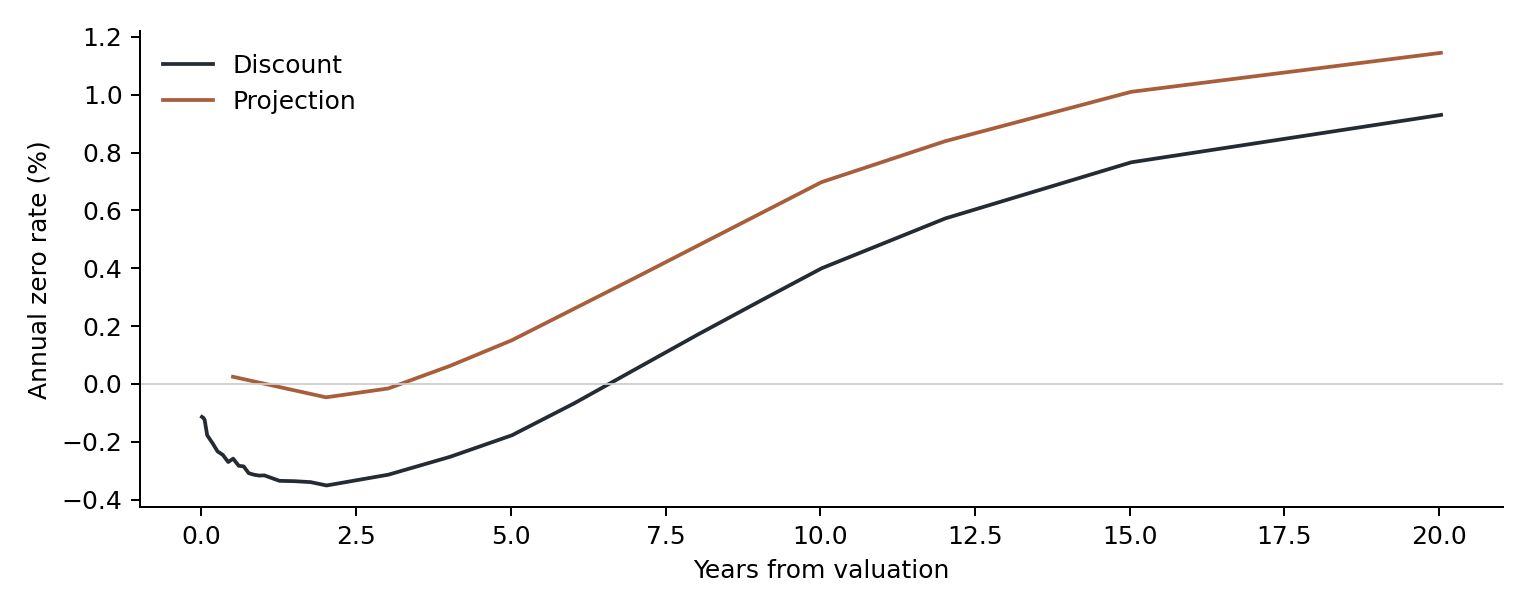

In [2]:
calibration = pd.DataFrame(result["calibration"])
print(calibration[["curve", "tenor", "rate", "implied_rate", "error_bp"]].to_string(index=False))
display(Image(filename="outputs/curves.png"))

## 2  Value a payment before valuing the portfolio

The **notional** is the amount used to calculate interest; these swaps do not
exchange the notional itself. For a floating payment, the model first estimates
the rate from projection factors at the start and end of its accrual period:

$$\text{forward rate}=\frac{P(\text{start})/P(\text{end})-1}{\text{year fraction}}.$$

It then multiplies the rate by the notional and year fraction. The discount
factor converts the resulting payment to present value. A pay-fixed trade has
negative fixed payments and positive floating payments before allowing for a
negative rate. A receive-fixed trade reverses these signs.

In [3]:
flows = pd.DataFrame(result["cashflows"])
print(flows[flows.trade_id == "S1"].head(5).to_string(index=False))
trades = pd.DataFrame(result["trades"])
print("\nPortfolio contracts and values")
print(trades.iloc[:4][["trade_id", "notional", "payer", "fixed_rate", "par_rate", "pv"]].to_string(index=False))
print(f"\nPortfolio value: EUR {trades.iloc[:4].pv.sum():,.2f}")

trade_id      leg      start        end   pay_date  year_fraction   notional  sign      rate  projection_start  projection_end  discount_factor     cash_flow            pv
      S1    Fixed 2016-03-09 2017-03-09 2017-03-09       1.000000 35000000.0     1  0.010000          0.999977        1.000281         1.003524 350000.000000 351233.437594
      S1    Fixed 2017-03-09 2018-03-09 2018-03-09       1.000000 35000000.0     1  0.010000          1.000281        1.000894         1.007285 350000.000000 352549.581325
      S1    Fixed 2018-03-09 2019-03-11 2019-03-11       1.005556 35000000.0     1  0.010000          1.000894        1.000239         1.009569 351944.444444 355312.319165
      S1 Floating 2016-03-09 2016-09-09 2016-09-09       0.511111 35000000.0    -1  0.000088          0.999977        0.999933         1.001671  -1571.866601  -1574.493887
      S1 Floating 2016-09-09 2017-03-09 2017-03-09       0.502778 35000000.0    -1 -0.000692          0.999933        1.000281         1.003

The `payer` flag is +1 for pay fixed and -1 for receive fixed. **Par rate**
means the fixed rate that would give a new trade a zero initial clean value.
The original contracts use different fixed rates, so their starting values are
not zero. Those values are not realised profits.

All portfolio trades start on 9 March 2016. Their first rate fixing lies after
valuation, so no past fixing is needed. The pricer rejects trades requiring a
historical fixing rather than substituting a forecast.

## 3  Measure exposure to each market quote

One **basis point**, or bp, is 0.01 percentage point: moving a rate from 1.00%
to 1.01% is a one-bp increase. The model moves each of the 40 quotes up and down
by 1 bp and rebuilds both curves each time. Half the difference in value gives
the central **PV01**, measured in euros per bp.

Adding these signed sensitivities gives the first-order response when every
quote rises together. Positive and negative exposures can cancel in that sum;
they can reappear if short and long rates move in different directions.

In [4]:
risk = pd.DataFrame(result["risk"])
print(risk.reindex(risk.Unhedged.abs().sort_values(ascending=False).index)
      [["curve", "tenor", "Unhedged"]].head(8).to_string(index=False))
print(f"\nTotal parallel PV01: EUR {risk.Unhedged.sum():,.2f} per bp")

curve tenor      Unhedged
EUR6M   12Y -23041.267899
EUR6M    7Y  17546.879268
EUR6M    3Y  -9775.159277
EUR6M    5Y   7266.658185
EUR6M    4Y  -1084.319394
EUR6M   15Y   -789.356086
EUR6M   10Y    648.662836
EUR1D   12Y   -143.465642

Total parallel PV01: EUR -9,804.03 per bp


## 4  Size the hedges against a stated objective

The **one-swap hedge** chooses a 10-year pay-fixed notional that cancels total
parallel PV01. The **three-swap hedge** uses 2-, 5- and 10-year swaps. It also
requires zero parallel PV01, then minimises the sum of squared sensitivities
to individual quotes. Equal weighting of quotes is an explicit modelling
choice; this is not a statistical forecast of future losses.

Hedge coupons are set at their par rates. A positive signed notional means pay
fixed; a negative amount means receive fixed. Entry cost is an assumed adverse
0.5 bp adjustment to each hedge's fixed rate, valued once using its annuity.

     policy trade_id  signed_notional  fixed_rate        cost
   One swap      H10     9.847001e+06    0.007064 4902.239961
Three swaps       H2     3.514736e+07   -0.000458 3533.730714
Three swaps       H5    -6.246360e+06    0.001658 1573.778469
Three swaps      H10     5.921347e+06    0.007064 2947.889025

Policy comparison
     policy  parallel_pv01    risk_norm  gross_hedge_notional  entry_cost
   Unhedged  -9.804026e+03 31455.508387          0.000000e+00    0.000000
   One swap  -1.818989e-12 32707.204052          9.847001e+06 4902.239961
Three swaps  -1.637090e-11 31672.010548          4.731507e+07 8055.398208


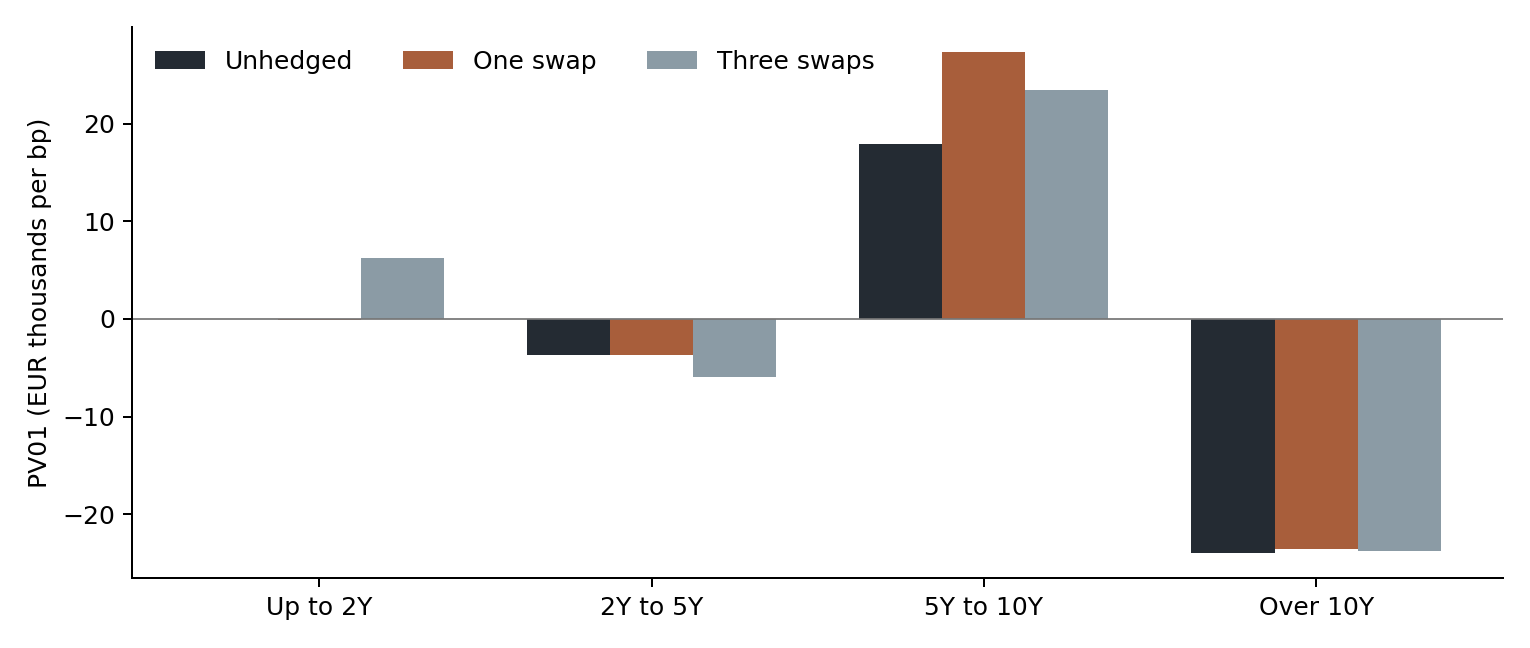

In [5]:
print(pd.DataFrame(result["hedge_positions"]).to_string(index=False))
print("\nPolicy comparison")
print(pd.DataFrame(result["summary"])[["policy", "parallel_pv01", "risk_norm", "gross_hedge_notional", "entry_cost"]].to_string(index=False))
display(Image(filename="outputs/risk_by_maturity.png"))

The chart sums signed quote sensitivity within each maturity band and across
both curves; offsets can occur within a band. The complete matrix above and in
`outputs/risk.csv` retains each individual exposure.

The three-swap solution reduces the squared-risk objective relative to the
one-swap solution, but it uses much more gross notional. An unconstrained
least-squares calculation would leave a large parallel exposure, which is why
the zero-parallel-risk constraint is explicit.

In [6]:
print("Unconstrained least-squares diagnostic only")
print(f"Parallel PV01: EUR {result['metadata']['unconstrained_parallel_pv01']:,.2f} per bp")
print("This unconstrained position is not one of the recommended policies.")

Unconstrained least-squares diagnostic only
Parallel PV01: EUR -16,567.32 per bp
This unconstrained position is not one of the recommended policies.


## 5  Reprice meaningful market moves

Each scenario changes input quotes and rebuilds both curves. A **steeper**
curve lowers quotes through two years by 25 bp, raises quotes from 15 years
onward by 25 bp, and connects the intervening maturities with a straight line.
The flatter scenario reverses those changes. Two further scenarios move only
the discount quotes or only the projection quotes.

Full repricing includes the nonlinear response that a first-order sensitivity
estimate misses. The residual is full repricing minus that approximation.

policy                       One swap  Three swaps   Unhedged
scenario                                                     
Discount quotes up 25 bp    -22069.26    -25263.14  -17239.35
Flatter curve               232457.89    386454.19  299655.84
Parallel down 50 bp           3185.53      5312.17  512501.49
Parallel up 50 bp             2454.74      4334.27 -469202.13
Projection quotes up 25 bp   12446.61      9334.40 -227678.70
Steeper curve              -242077.06   -403477.78 -299872.63


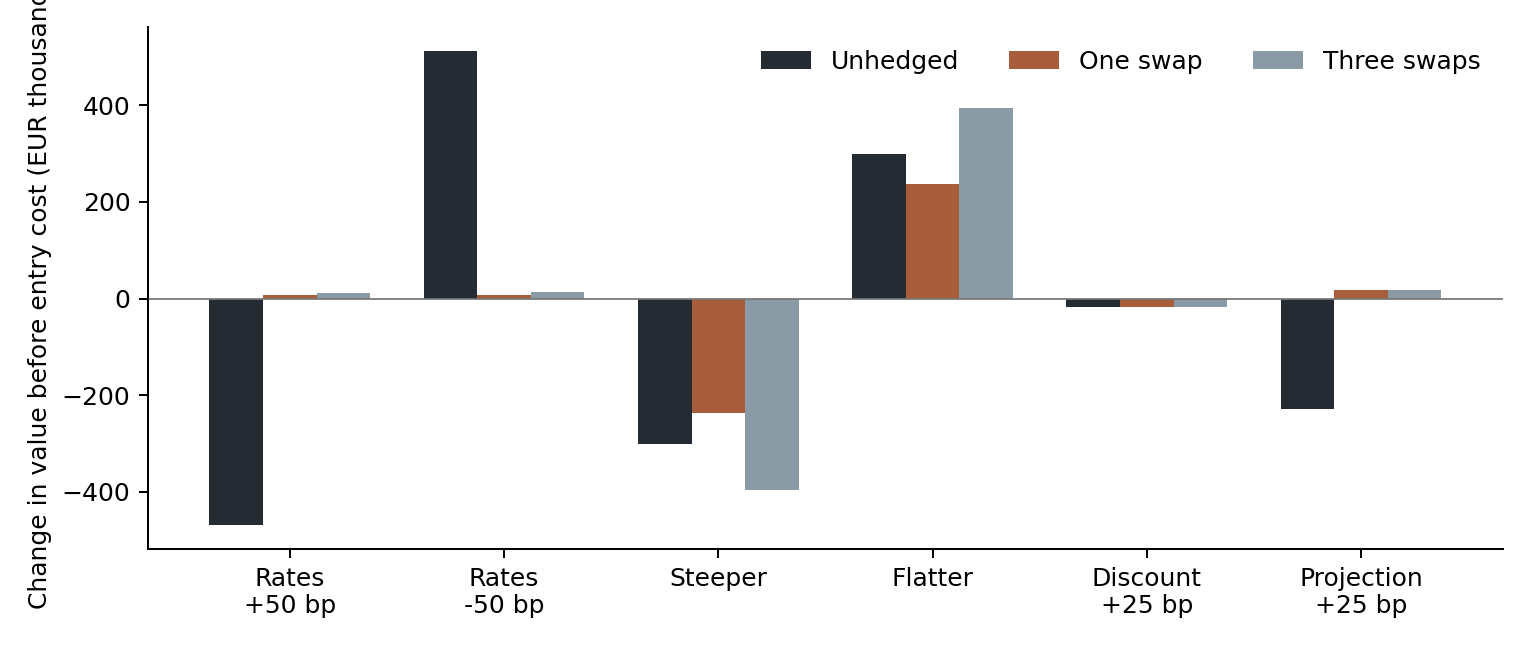

In [7]:
scenarios = pd.DataFrame(result["scenarios"])
print(scenarios.pivot(index="scenario", columns="policy", values="after_cost").round(2).to_string())
display(Image(filename="outputs/scenario_comparison.png"))

The one-swap hedge has a smaller maximum absolute change in value across
these selected scenarios than the unhedged book and the three-swap alternative.
However, the steepening scenario still loses about EUR 242,077 after the
assumed entry cost. Neither a zero parallel PV01 nor a lower least-squares
objective guarantees protection against every curve shape.

## 6  Explain the change from opening to closing value

This illustrative next-business-day case raises discount quotes by 4 bp and
projection quotes by 10 bp, then changes the valuation origin to 8 February
2016. It holds the calendar-date curves fixed when isolating time passage.
There are no payments between the two dates. These are chosen shocks, not
observed next-day market data.

Gross P&L equals closing value minus opening value plus cash received. The
bridge separates the time effect, the first-order market effect and the
remaining nonlinear and interaction effects. Entry cost is then deducted once.

In [8]:
pnl = pd.DataFrame(result["pnl"])
print(pnl[["policy", "time_effect", "linear_market_effect", "residual", "gross_pnl", "entry_cost", "net_pnl"]].round(2).to_string(index=False))
assert np.allclose(pnl.gross_pnl, pnl.time_effect + pnl.linear_market_effect + pnl.residual)
assert np.allclose(pnl.net_pnl, pnl.gross_pnl - pnl.entry_cost)
print("\nP&L bridge reconciles.")

     policy  time_effect  linear_market_effect  residual  gross_pnl  entry_cost   net_pnl
   Unhedged       -14.85             -93858.98    344.12  -93529.71        0.00 -93529.71
   One swap       -14.85               4163.74    121.16    4270.05     4902.24   -632.19
Three swaps       -14.85               4173.60    203.44    4362.19     8055.40  -3693.21

P&L bridge reconciles.


## 7  Conclusion and reproducibility

For the aim of removing the initial parallel sensitivity in this case, the
10-year hedge is the preferred candidate. It needs less notional and lower
assumed entry cost than the three-swap alternative and performs better across
the chosen stress set. Curve-shape risk remains material.

The clean value assumes overnight discounting and does not include counterparty
default, funding or margin adjustments. A different risk objective, hedge
universe or set of market scenarios can lead to different hedge positions.

Run `python -m unittest discover -s tests -v` for the 19 checks covering quote
reproduction, date conventions, direct pricing arithmetic, payment sums,
sensitivity convergence, hedge constraints and P&L reconciliation. The project
does not claim numerical equivalence to ORE or QuantLib; those company and
open-source examples informed the workflow and conventions. Source links,
input hashes and setup instructions are in `README.md` and
`data/source/provenance.json`.